In [2]:
import pandas as pd
#Daten Laden
df = pd.read_csv("data/rossmann/train_filtered.csv", low_memory=False)
df["Date"] = pd.to_datetime(df["Date"])   # Text -> echtes Datum

print(df.head()) # erste 5 zeile in console
print(df["Date"].min(), df["Date"].max())


   Store  DayOfWeek       Date  Sales  Customers  Open  Promo StateHoliday  \
0      1          5 2015-07-31   5263        555     1      1            0   
1      2          5 2015-07-31   6064        625     1      1            0   
2      3          5 2015-07-31   8314        821     1      1            0   
3      1          4 2015-07-30   5020        546     1      1            0   
4      2          4 2015-07-30   5567        601     1      1            0   

   SchoolHoliday  
0              1  
1              1  
2              1  
3              1  
4              1  
2013-01-01 00:00:00 2015-07-31 00:00:00


In [3]:
#Stores auswählen und filtern
stores = [1, 2, 3]
df = df[df["Store"].isin(stores)]
df = df[(df["Open"] == 1) & (df["Sales"] > 0)] # nur Tage, an denen geöffnet war

In [4]:
store_id = 1 # Stores Ins Prophet-Format bringen
data = (
    df[df["Store"] == store_id][["Date", "Sales"]]
    .rename(columns={"Date": "ds", "Sales": "y"})
    .sort_values("ds")
)
#was ganz vorne in ausgabe steht ist zeile nummer in CSV file 
print(data.head())

             ds     y
2820 2013-01-02  5530
2817 2013-01-03  4327
2814 2013-01-04  4486
2811 2013-01-05  4997
2805 2013-01-07  7176


In [7]:
from prophet import Prophet
# Trainieren und 30 Tage vorhersagen
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,   # wir haben nur Tageswerte
)
model.fit(data)

future = model.make_future_dataframe(periods=30)   # Vergangenheit + 30 Tage
forecast = model.predict(future)

print(forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(10))

19:07:32 - cmdstanpy - INFO - Chain [1] start processing
19:07:32 - cmdstanpy - INFO - Chain [1] done processing


            ds         yhat   yhat_lower   yhat_upper
801 2015-08-21  4185.766487  3121.502612  5223.758857
802 2015-08-22  4399.677287  3327.945377  5517.133094
803 2015-08-23  4403.700965  3327.019796  5449.573509
804 2015-08-24  4650.027968  3560.527836  5733.295871
805 2015-08-25  4163.026382  3056.327312  5280.315136
806 2015-08-26  4047.213145  3002.397487  5086.443700
807 2015-08-27  3956.271608  2913.986468  5067.771634
808 2015-08-28  4206.530536  3167.178185  5207.905318
809 2015-08-29  4404.618532  3280.251163  5409.829398
810 2015-08-30  4391.301033  3361.047177  5523.468433


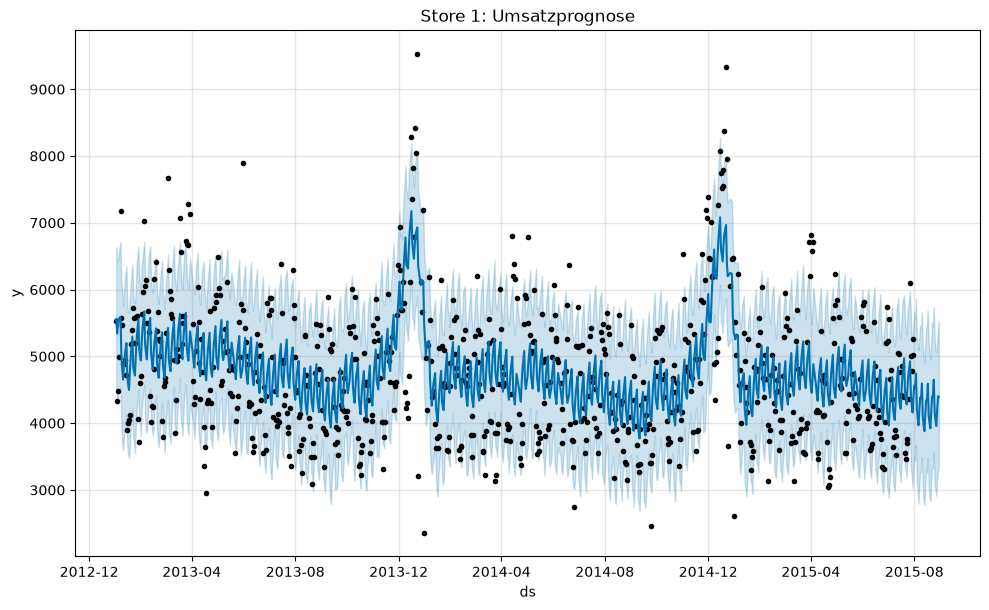

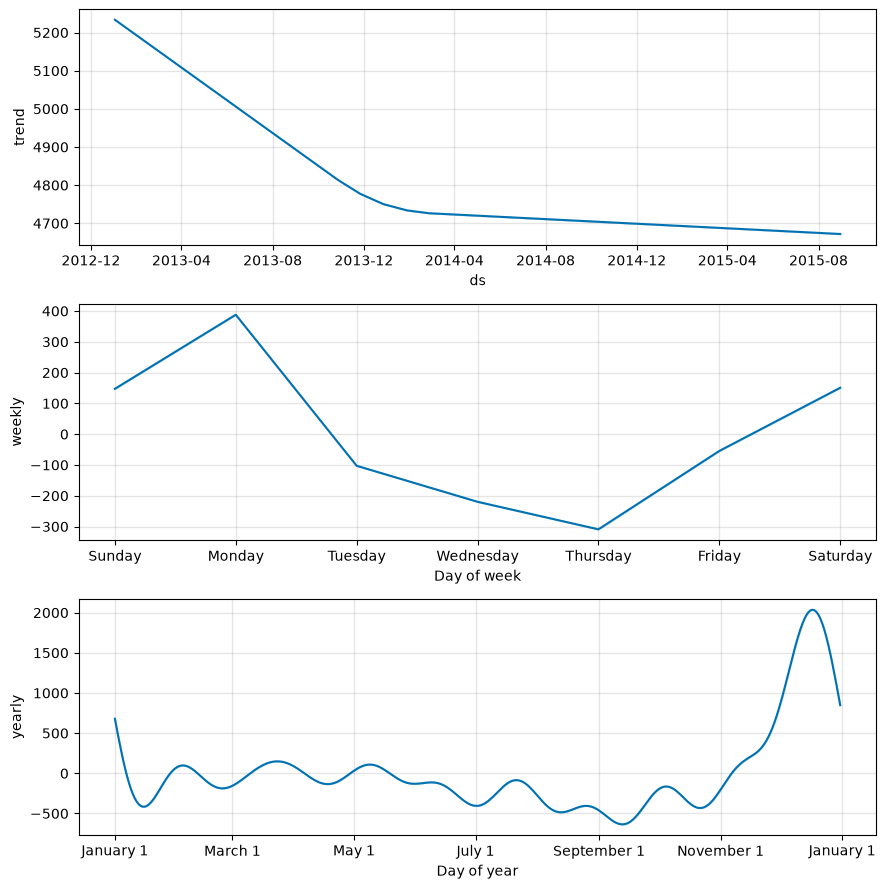

In [8]:
import matplotlib.pyplot as plt
#Visualisieren (Trend und Saison)
fig1 = model.plot(forecast)
plt.title(f"Store {store_id}: Umsatzprognose")

fig2 = model.plot_components(forecast)   # Trend, Woche, Jahr
plt.show()

In [9]:
from sklearn.metrics import mean_absolute_error

cutoff = data["ds"].max() - pd.Timedelta(days=30)
train = data[data["ds"] <= cutoff]
test = data[data["ds"] > cutoff]

m = Prophet(yearly_seasonality=True, weekly_seasonality=True,
            daily_seasonality=False).fit(train)
fc = m.predict(m.make_future_dataframe(periods=35))   # etwas mehr, damit alle Testtage drin sind

check = test.merge(fc[["ds", "yhat"]], on="ds")
mae = mean_absolute_error(check["y"], check["yhat"])
print(f"MAE: {mae:.0f} € pro Tag")
print(f"Fehler in Prozent: {mae / check['y'].mean():.1%}")

19:31:10 - cmdstanpy - INFO - Chain [1] start processing
19:31:10 - cmdstanpy - INFO - Chain [1] done processing


MAE: 616 € pro Tag
Fehler in Prozent: 13.8%


In [10]:
def forecast_store(df, store_id, days=30):
    data = (
        df[df["Store"] == store_id][["Date", "Sales"]]
        .rename(columns={"Date": "ds", "Sales": "y"})
    )
    model = Prophet(yearly_seasonality=True, weekly_seasonality=True,
                    daily_seasonality=False)
    model.fit(data)
    fc = model.predict(model.make_future_dataframe(periods=days))
    fc["Store"] = store_id
    return model, fc

results = []
for s in [1, 2, 3]:
    _, fc = forecast_store(df, s)
    results.append(fc[["Store", "ds", "yhat", "yhat_lower", "yhat_upper"]])

pd.concat(results).to_csv("data/rossmann/forecasts.csv", index=False)

20:14:32 - cmdstanpy - INFO - Chain [1] start processing
20:14:32 - cmdstanpy - INFO - Chain [1] done processing
20:14:32 - cmdstanpy - INFO - Chain [1] start processing
20:14:32 - cmdstanpy - INFO - Chain [1] done processing
20:14:32 - cmdstanpy - INFO - Chain [1] start processing
20:14:33 - cmdstanpy - INFO - Chain [1] done processing
